### PAKISTAN LAW RAG ASSISTANT

In [1]:
from langgraph.graph import StateGraph, START, END
from langchain_qdrant import QdrantVectorStore
from langchain_core.output_parsers import StrOutputParser
from langchain_huggingface import HuggingFaceEmbeddings
import os 
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from operator import itemgetter


load_dotenv()

QDRANT_URL = os.getenv("QDRANT_URL")
QDRANT_API_KEY =  os.getenv("QDRANT_API_KEY")
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

d:\Hamza Ali\Motor Vehicle RAG\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### INITIALIZE LLM GEMINI 2.5 FLASH

In [2]:
llm = ChatGoogleGenerativeAI(
    model='gemini-2.5-flash',
    api_key = "PASTE YOUR ENV KEY"
)

### EMBEDDING MODEL FROM HUGGING FACE

In [ ]:
embedding_model = HuggingFaceEmbeddings(
    model_name="BAAI/bge-small-en-v1.5"
)

In [ ]:
vector_store = QdrantVectorStore.from_existing_collection(
    collection_name="better_rag",
    embedding=embedding_model,
    url=QDRANT_URL,
    api_key=QDRANT_API_KEY,
)

retriever = vector_store.as_retriever(
    search_type="similarity_score_threshold",
    search_kwargs={"score_threshold": 0.8},)

In [1]:
from langchain_core.prompts import ChatPromptTemplate

template = """
You are a legal RAG assistant for Pakistan Motor Vehicle Law. Use ONLY the provided document context to answer questions.

Instructions:
- Read the ENTIRE Context first, all chunks together, before answering — do not answer from the first matching sentence you find.
- Some chunks may be incomplete or start mid-sentence (e.g. a chunk that begins with "(a)..." with no heading above it). If you see a list item like (a), (b), (c) with no heading, look through the OTHER provided chunks for the matching section number or heading that these list items belong to, and combine them into one full answer.
- If a chunk contains a list of items (a), (b), (c), (d) etc., these are usually ALL PART OF THE SAME RULE — do not treat them as unrelated or skip them just because the heading isn't in that exact chunk. Always report the full list together, in order.
- Do NOT prefer a chunk just because it is a complete standalone sentence — a fragmented or listed clause can still be the correct, more important answer. Judge relevance by content match to the question, not by which chunk reads more smoothly.
- Use ONLY the information found in the Context.
- If the answer is not present in the Context, say:
    "I couldn't find that information in the provided document."
- Do NOT make up facts or use outside knowledge.
- If possible, mention the page number when it is available in the context metadata.
- Keep your answer clear, accurate, and well formatted.
- Use simple language that any professional person can understand.
- Use bullet points when appropriate.
- Answer in a natural, conversational way as a helpful legal assistant.
- Provide a clear, complete response instead of a short one-line answer.

If multiple sections are relevant, prioritize the section whose title most closely matches the question, and quote its full clause (including all sub-points a, b, c, d, etc.) before mentioning related sections.

THE CONTEXT HAS PAGE NUMBER AT START SO FROM YOU GIVE ANSWER ALSO GIVE IT PAGE NUMBER

Context:
{Context}

Question:
{Input}

Answer:
"""

prompt = ChatPromptTemplate.from_template(template)

d:\Hamza Ali\Motor Vehicle RAG\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
prompt_refiner = """ 
You are a prompt refiner for a legal RAG assistant focused on Pakistan Motor Vehicle Law.

Your task:
- Improve the user query so retrieval finds the most relevant legal context.
- Correct spelling, grammar, and phrasing without changing meaning.
- Keep the refined query close in length to the original.
- Add only the keywords needed to improve retrieval accuracy.
- Do not invent new facts or change the user’s intent.
- Return only the refined query, not an answer.

Example:
    Input: can i drive moter cycle without helmet
    Refined: DRIVE MOTORCYCLE WITHOUT HELMET AND FINE APPLIES DRIVE MOTER WITHOUT HELMET

Input: {Input_q}
"""

refine_question = ChatPromptTemplate.from_template(prompt_refiner)
chain_for_refine = refine_question | llm | StrOutputParser()

In [ ]:
print(chain_for_refine.invoke({"Input_q":'drive moter cycle without license'}))

In [3]:
class Global_Variable(TypedDict):
    Input_q : str
    Input : str
    answer : str


In [4]:
def refiner(state : Global_Variable):
    result = chain_for_refine.invoke({"Input_q":state['Input_q']})
    state['Input'] = result
    return state

In [5]:
def get_answer(state : Global_Variable):
    qf = itemgetter("Input")

    setup = {
        "Input" : qf,
        "Context" : qf | retriever
    }

    chain = setup | prompt |llm | StrOutputParser()
    # Input = state['refine_Input']
    state['answer'] = chain.invoke({"Input":state['Input']})
    return state


In [8]:
workflow = StateGraph(Global_Variable)

In [9]:
workflow.add_node("get_answer",get_answer)

workflow.add_edge(START,'get_answer')
workflow.add_edge('get_answer',END)

In [10]:
graph = workflow.compile()

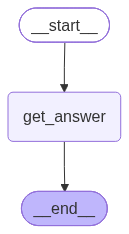

In [11]:
graph

#### GIVE QUESTION TO WORKFLOW

In [96]:
result = graph.invoke({"Input":"what if someone drive moter on wrong side of road and what fine "})

In [97]:
from IPython.display import display , Markdown

display(Markdown(result['answer']))

Based on the provided document, Section 75-A, titled "Driving motor vehicle on wrong side of the road," states that:

"No person shall drive a motor vehicle, or cause or allow a motor vehicle to be driven on the wrong side of the road or part thereof that has been declared or designated as one-way by the Government or the competent authority, as the case may be, whether by means of traffic signs, traffic signals, road markings, or any other prescribed method of traffic control." (page_number = 56)

There are certain exemptions to this rule:
*   Emergency vehicles engaged in emergency duties are exempted.
*   Government or competent authority may authorize vehicles to travel in the opposite direction for public works, planned traffic diversions, or other justifiable reasons, which must be recorded in writing.
*   A police officer may, in an emergency, allow vehicles to travel in the opposite direction to ensure public safety, facilitate emergency response, or prevent traffic obstruction. (page_number = 56)

However, the provided document does not specify any fine or penalty for driving a motor vehicle on the wrong side of the road. I couldn't find that information in the provided document.